# Match Initialization

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
from kloppy import sportscode, metrica

# 1. Cargar el CSV de datos
CSV_PATH = "C:/Users/nerir/OneDrive/Escritorio/exps_programacio/more-than-a-hack-2027/data/dataframe_hackaton_final.csv"  # <-- Pon aquí la ruta a tu CSV
df = pd.read_csv(CSV_PATH)

print(f"Dataset cargado: {df.shape[0]} filas y {df.shape[1]} columnas")

# 2. Diccionario de configuración

VIDEO_FRAMES = 199319

# Frames de las partes
MATCH_META = {"offsets": {1: 1702057, 2: 1702058},
              "halves": {1: (1713242, 1792708), 2: (1812866, 1892255)},
              "kickoffs": {1: {"minute": 7, "second": 27, "frame": 11}, 2: {"minute": 75, "second": 49, "frame": 16}}}
real_halves = {half: (
        (MATCH_META["kickoffs"][half]["minute"] * 60 + MATCH_META["kickoffs"][half]["second"]) * 25 + MATCH_META["kickoffs"][half]["frame"],
        MATCH_META["halves"][half][1] - MATCH_META["offsets"][half])
    for half in [1, 2]}


# 3. Asegurar que 'frame_id' en el df tiene restado el offset (para que coincida con real_halves)
if df["frame_id"].min() > 1000000:
    print("Restando offsets a 'frame_id'...")
    df["frame_id"] = df["frame_id"] - df["period_id"].map(MATCH_META["offsets"])

print("Rangos de frame_id en el CSV por parte:")
print(df.groupby("period_id")["frame_id"].agg(["min", "max", "count"]))
print("Rangos esperados en real_halves:", real_halves)

C:\Users\nerir\AppData\Local\Temp\ipykernel_6748\1569269232.py:11: DtypeWarning: Columns (144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(CSV_PATH)


Dataset cargado: 199319 filas y 265 columnas
Rangos de frame_id en el CSV por parte:
           min     max   count
period_id                     
1            1  199319  199319
Rangos esperados en real_halves: {1: (11186, 90651), 2: (113741, 190197)}


In [3]:
df_filtrado = df[df['set_pieces'].notna() & df['frame_id'].between(85000, 90651)]
display(df_filtrado)

,period_id,timestamp,frame_id,ball_x,ball_y,ball_speed,1_x,1_y,1_s,2_x,...,37_y_vel,38_y_vel,39_y_vel,40_y_vel,41_y_vel,42_y_vel,43_y_vel,44_y_vel,45_y_vel,46_y_vel
84999,1,0 days 00:56:40,85000,0.94849,0.53836,0.002550,0.53071,0.62398,1.006316,NaN,...,NaN,NaN,NaN,NaN,0.00250,NaN,0.00600,NaN,NaN,-0.00100
85000,1,0 days 00:56:40.040000,85001,0.94856,0.53821,0.004138,0.53047,0.62454,1.023306,NaN,...,NaN,NaN,NaN,NaN,0.00225,NaN,0.00625,NaN,NaN,-0.00200
85001,1,0 days 00:56:40.080000,85002,0.94871,0.53801,0.006250,0.53022,0.62513,1.041425,NaN,...,NaN,NaN,NaN,NaN,0.00225,NaN,0.00675,NaN,NaN,-0.00250
85002,1,0 days 00:56:40.120000,85003,0.94893,0.53775,0.008515,0.52998,0.62572,1.060547,NaN,...,NaN,NaN,NaN,NaN,0.00225,NaN,0.00700,NaN,NaN,-0.00350
85003,1,0 days 00:56:40.160000,85004,0.94923,0.53743,0.010966,0.52973,0.62633,1.080521,NaN,...,NaN,NaN,NaN,NaN,0.00200,NaN,0.00725,NaN,NaN,-0.00475
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86443,1,0 days 00:57:37.760000,86444,0.80952,0.80860,0.027102,NaN,NaN,NaN,NaN,...,NaN,0.07625,NaN,NaN,0.02150,NaN,0.00850,NaN,NaN,0.00250
86444,1,0 days 00:57:37.800000,86445,0.81007,0.80905,0.017766,NaN,NaN,NaN,NaN,...,NaN,0.07525,NaN,NaN,0.02125,NaN,0.00800,NaN,NaN,0.00100
86445,1,0 days 00:57:37.840000,86446,0.81051,0.80915,0.011281,NaN,NaN,NaN,NaN,...,NaN,0.07400,NaN,NaN,0.02125,NaN,0.00725,NaN,NaN,-0.00025
86446,1,0 days 00:57:37.880000,86447,0.81085,0.80893,0.010124,NaN,NaN,NaN,NaN,...,NaN,0.07250,NaN,NaN,0.02100,NaN,0.00700,NaN,NaN,-0.00125


In [4]:
import numpy as np
import pandas as pd

# ==========================================
# CONFIGURACIÓN DE VARIABLES
# ==========================================

# Variables generales
FPS = 25               # Frames por segundo
VIDEO_FRAMES = 199319  # Frames totales del video
PITCH_CENTER_X = 0.5   # Cambiar a 52.5 si el campo va de 0 a 105
PITCH_CENTER_Y = 0.5   # Cambiar a 34.0 si el campo va de 0 a 68

# Frames de las partes
MATCH_META = {"offsets": {1: 1702057, 2: 1702058},
              "halves": {1: (1713242, 1792708), 2: (1812866, 1892158)},
              "kickoffs": {1: {"minute": 7, "second": 27, "frame": 11}, 2: {"minute": 75, "second": 49, "frame": 16}}}
real_halves = {half: (
        (MATCH_META["kickoffs"][half]["minute"] * 60 + MATCH_META["kickoffs"][half]["second"]) * 25 + MATCH_META["kickoffs"][half]["frame"],
        MATCH_META["halves"][half][1] - MATCH_META["offsets"][half])
    for half in [1, 2]}

# Etiquetas y rangos de jugadores por equipo
HOME_TAG = "H"   # Cambia a "H" o el string exacto que os pidan en el submission
AWAY_TAG = "A"   # Cambia a "A" o el string exacto que os pidan en el submission
HOME_IDS = list(range(1, 25))   # Jugadores del 1 al 24
AWAY_IDS = list(range(25, 47))  # Jugadores del 25 al 46

# Variables threshoold
TH_BALL_SPEED = 0.1




# ==========================================
# PASO 0: PONER LAS 'X' Y SEPARAR PARTES
# ==========================================
def init_frames_with_X(halves_dict=real_halves, n_video_frames=VIDEO_FRAMES):
    """
    Inicializa el DataFrame de predicciones para todo el vídeo.
    Etiqueta con 'X' los tramos fuera de juego (pre-partido, descanso y post-partido)
    y deja en None los frames correspondientes a la 1ª y 2ª parte.

    Args:
        halves_dict (dict): Diccionario {1: (start_1, end_1), 2: (start_2, end_2)} en frames reales.
        n_video_frames (int): Número total de frames del vídeo.

    Returns:
        pd.DataFrame: DataFrame con columnas ['frame', 'label'].
    """

    # 1. Crear el DataFrame con las dos columnas: 'frame' (0 a n_video_frames - 1) y 'label'
    # Inicializamos todo con "X" por defecto
    df_results = pd.DataFrame({
        "frame": range(n_video_frames),
        "label": "D"
    })
    
    # 2. Dejar vacíos (None) los frames que sí corresponden a la 1ª y 2ª parte
    for half, (start_frame, end_frame) in halves_dict.items():
        df_results.loc[start_frame:end_frame, "label"] = None
        
    return df_results




# ==========================================
# PASO 1: FUNCIÓN DE KICK OFF (START)
# ==========================================
def kick_off(df, start_frame, max_wait_frames=500):
    """
    Analiza el saque de centro al inicio de una parte para determinar hacia dónde
    ataca cada equipo, quién empieza con la posesión y en qué frame se pone el balón en juego.

    Args:
        df (pd.DataFrame): DataFrame con los datos de tracking y velocidades.
        start_frame (int): Frame real en el que comienza la parte.
        max_wait_frames (int, optional): Límite de frames a explorar hasta el golpeo inicial.

    Returns:
        tuple:
            - attack_dir (dict): Dirección de ataque por equipo ({'Home': 1/-1, 'Away': -1/1}).
            - starting_team (str): Etiqueta del equipo que realiza el saque ('Home' o 'Away').
            - play_start_frame (int): Frame exacto en el que el balón empieza a moverse.
    """

    # 0. Localizar el frame de inicio en el df
    row_mask = df["frame_id"] == start_frame
    if row_mask.any():
        row = df.loc[row_mask].iloc[0]
    else:
        # Por si falta algún frame exacto, cogemos el primero disponible a partir de start_frame
        row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    # Columnas X de cada equipo
    home_x_cols = [f"{i}_x" for i in HOME_IDS if f"{i}_x" in df.columns]
    away_x_cols = [f"{i}_x" for i in AWAY_IDS if f"{i}_x" in df.columns]


    # 1. Detectar donde ataca cada equipo (Posición jugadores a banda y banda)
    home_median_x = row[home_x_cols].median()
    away_median_x = row[away_x_cols].median()
    # Si la mediana de X es menor, están en el campo izquierdo (X < 0.5) y atacan hacia la derecha (+1)
    if home_median_x < away_median_x:
        attack_dir = {HOME_TAG: 1, AWAY_TAG: -1}
    else:
        attack_dir = {HOME_TAG: -1, AWAY_TAG: 1}

  
    # 2. Definir quien empieza con la posesión (3 jugadores más cercanos a 0.5, 0.5)
    player_distances = []
    for pid in HOME_IDS + AWAY_IDS:
        px = row.get(f"{pid}_x", np.nan)
        py = row.get(f"{pid}_y", np.nan)
        if pd.notna(px) and pd.notna(py):
            dist = np.hypot(px - PITCH_CENTER_X, py - PITCH_CENTER_Y)
            team = HOME_TAG if pid in HOME_IDS else AWAY_TAG
            player_distances.append((dist, team, pid))
    # Ordenar por distancia al centro y coger el más cercano
    player_distances.sort(key=lambda x: x[0])
    starting_team = [item[1] for item in player_distances[:1]]



    # 3. Detectar cuando empieza a jugarse el balón (Cuando la pelota coge velocidad)
    window = df[
        (df["frame_id"] >= start_frame) & 
        (df["frame_id"] <= start_frame + max_wait_frames)
    ]
    dist_ball_center = np.hypot(
        window["ball_x"] - PITCH_CENTER_X, 
        window["ball_y"] - PITCH_CENTER_Y
    )
    # La pelota se juega cuando supera el umbral de velocidad 
    moving_mask = (window["ball_speed"] > TH_BALL_SPEED) 
    moving_frames = window.loc[moving_mask, "frame_id"]

    if not moving_frames.empty:
        play_start_frame = int(moving_frames.iloc[0])
    else:
        play_start_frame = start_frame

    return attack_dir, starting_team, play_start_frame


In [5]:
# 1. Probar Paso 0
df_results = init_frames_with_X(real_halves, VIDEO_FRAMES)
print("Conteo tras Paso 0 (solo X y None):")
print(df_results["label"].value_counts(dropna=False))
print("-" * 50)

# 2. Probar Paso 1 en ambas partes con tu función exacta
for half, (start_frame, end_frame) in real_halves.items():
  attack_dir, starting_team, play_start_frame = kick_off(
      df, start_frame
  )

  # Forzar que sean enteros puros para evitar problemas con .loc
  start_frame = int(start_frame)
  play_start_frame = int(play_start_frame)
  end_frame = int(end_frame)

  # 1. Rellenar con 'D' desde el inicio de la parte hasta el saque
  if play_start_frame > start_frame:
    df_results.loc[start_frame : play_start_frame - 1, "label"] = "D"

  # 2. Rellenar con el equipo que saca el resto de la parte
  df_results.loc[play_start_frame:end_frame, "label"] = str(starting_team)

  print(f"=== PARTE {half} (Inicia en frame {start_frame}) ===")
  print(f"  -> Dirección de ataque : {attack_dir}")

  print(f"  -> Equipo que saca     : {starting_team}")
  print(
      f"  -> Pelota en juego en  : Frame {play_start_frame}"
      f" ({play_start_frame - start_frame} frames en 'D')"
  )
  print()

print("-" * 50)
print("Conteo final en df_results tras Paso 0 y Paso 1:")
print(df_results["label"].value_counts(dropna=False))

Conteo tras Paso 0 (solo X y None):
label
None    155826
D        43493
Name: count, dtype: int64
--------------------------------------------------
=== PARTE 1 (Inicia en frame 11186) ===
  -> Dirección de ataque : {'H': 1, 'A': -1}
  -> Equipo que saca     : ['A']
  -> Pelota en juego en  : Frame 11189 (3 frames en 'D')

=== PARTE 2 (Inicia en frame 113741) ===
  -> Dirección de ataque : {'H': -1, 'A': 1}
  -> Equipo que saca     : ['H']
  -> Pelota en juego en  : Frame 113741 (0 frames en 'D')

--------------------------------------------------
Conteo final en df_results tras Paso 0 y Paso 1:
label
['A']    79463
['H']    76360
D        43496
Name: count, dtype: int64


In [6]:
print(real_halves)

{1: (11186, 90651), 2: (113741, 190100)}


In [7]:
h1_start = real_halves[1][0]
print("Transición en el inicio de la 1ª Parte:")
display(df_results.loc[h1_start - 3 : h1_start + 15])

h2_start = real_halves[2][0]
print("Transición en el inicio de la 2ª Parte:")
display(df_results.loc[h2_start - 3 : h2_start + 15])

Transición en el inicio de la 1ª Parte:


,frame,label
11183,11183,D
11184,11184,D
11185,11185,D
11186,11186,D
11187,11187,D
11188,11188,D
11189,11189,['A']
11190,11190,['A']
11191,11191,['A']
11192,11192,['A']


Transición en el inicio de la 2ª Parte:


,frame,label
113738,113738,D
113739,113739,D
113740,113740,D
113741,113741,['H']
113742,113742,['H']
113743,113743,['H']
113744,113744,['H']
113745,113745,['H']
113746,113746,['H']
113747,113747,['H']


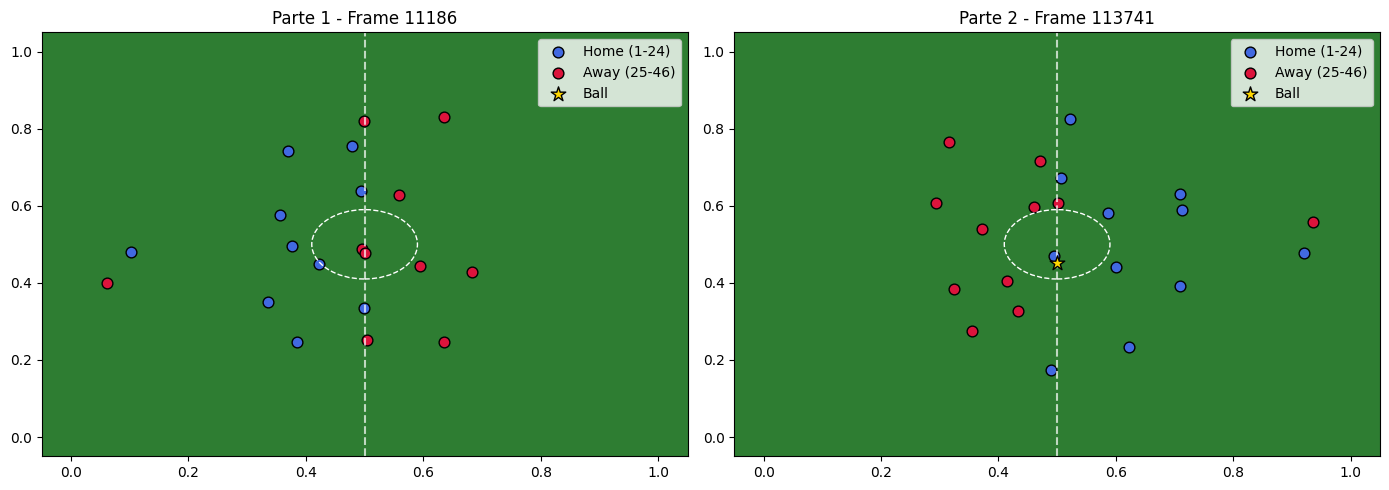

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (half, (start_frame, _)) in enumerate(real_halves.items()):
    ax = axes[idx]
    row = df[df["frame_id"] >= start_frame].iloc[0]
    
    # Pintar jugadores Home (1-24) en Azul
    hx = [row[f"{i}_x"] for i in HOME_IDS if f"{i}_x" in df.columns]
    hy = [row[f"{i}_y"] for i in HOME_IDS if f"{i}_y" in df.columns]
    ax.scatter(hx, hy, c="royalblue", label="Home (1-24)", s=60, edgecolors="black")
    
    # Pintar jugadores Away (25-46) en Rojo
    ax_x = [row[f"{i}_x"] for i in AWAY_IDS if f"{i}_x" in df.columns]
    ax_y = [row[f"{i}_y"] for i in AWAY_IDS if f"{i}_y" in df.columns]
    ax.scatter(ax_x, ax_y, c="crimson", label="Away (25-46)", s=60, edgecolors="black")
    
    # Pintar Pelota
    ax.scatter(row["ball_x"], row["ball_y"], c="gold", label="Ball", s=120, marker="*", edgecolors="black", zorder=5)
    
    # Dibujar líneas del campo [0, 1]
    ax.axvline(0.5, color="white", linestyle="--", alpha=0.7)
    circle = plt.Circle((0.5, 0.5), 0.09, color="white", fill=False, linestyle="--")
    ax.add_patch(circle)
    
    ax.set_facecolor("#2e7d32")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f"Parte {half} - Frame {int(row['frame_id'])}")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [9]:
home_x_cols = [f"{i}_x" for i in HOME_IDS if f"{i}_x" in df.columns]
away_x_cols = [f"{i}_x" for i in AWAY_IDS if f"{i}_x" in df.columns]

for half, (start_frame, _) in real_halves.items():
    row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    
    # Valores de X sin NaNs
    h_vals = row[home_x_cols].dropna()
    a_vals = row[away_x_cols].dropna()
    
    print(f"=== PARTE {half} (Frame {int(row['frame_id'])}) ===")
    print(f"  Home ({len(h_vals)} jug.) -> Mediana X: {h_vals.median():.3f} | Media X: {h_vals.mean():.3f} | Min X (Portero): {h_vals.min():.3f} | Max X: {h_vals.max():.3f}")
    print(f"  Away ({len(a_vals)} jug.) -> Mediana X: {a_vals.median():.3f} | Media X: {a_vals.mean():.3f} | Min X: {a_vals.min():.3f} | Max X (Portero): {a_vals.max():.3f}")
    print()

=== PARTE 1 (Frame 11186) ===
  Home (10 jug.) -> Mediana X: 0.381 | Media X: 0.382 | Min X (Portero): 0.103 | Max X: 0.499
  Away (10 jug.) -> Mediana X: 0.532 | Media X: 0.517 | Min X: 0.061 | Max X (Portero): 0.683

=== PARTE 2 (Frame 113741) ===
  Home (11 jug.) -> Mediana X: 0.600 | Media X: 0.625 | Min X (Portero): 0.490 | Max X: 0.920
  Away (11 jug.) -> Mediana X: 0.415 | Media X: 0.444 | Min X: 0.294 | Max X (Portero): 0.937



In [10]:
for half, (start_frame, _) in real_halves.items():
    row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    
    left_side = []   # Jugadores en X < 0.5
    right_side = []  # Jugadores en X >= 0.5
    
    for i in range(1, 47):
        px = row.get(f"{i}_x", np.nan)
        if pd.notna(px):
            if px < 0.5:
                left_side.append((i, round(px, 3)))
            else:
                right_side.append((i, round(px, 3)))
                
    print(f"=== PARTE {half} (Frame {int(row['frame_id'])}) - Total activos: {len(left_side) + len(right_side)} ===")
    print(f"  Lado Izquierdo (X < 0.5) [{len(left_side)} jug.]: {[x[0] for x in left_side]}")
    print(f"  Lado Derecho   (X >= 0.5) [{len(right_side)} jug.]: {[x[0] for x in right_side]}")
    print()

=== PARTE 1 (Frame 11186) - Total activos: 20 ===
  Lado Izquierdo (X < 0.5) [13 jug.]: [2, 3, 4, 6, 9, 11, 12, 15, 16, 24, 29, 34, 46]
  Lado Derecho   (X >= 0.5) [7 jug.]: [30, 31, 32, 35, 37, 43, 45]

=== PARTE 2 (Frame 113741) - Total activos: 22 ===
  Lado Izquierdo (X < 0.5) [11 jug.]: [1, 17, 25, 31, 34, 35, 37, 39, 40, 41, 42]
  Lado Derecho   (X >= 0.5) [11 jug.]: [3, 4, 6, 8, 14, 15, 18, 19, 24, 36, 46]



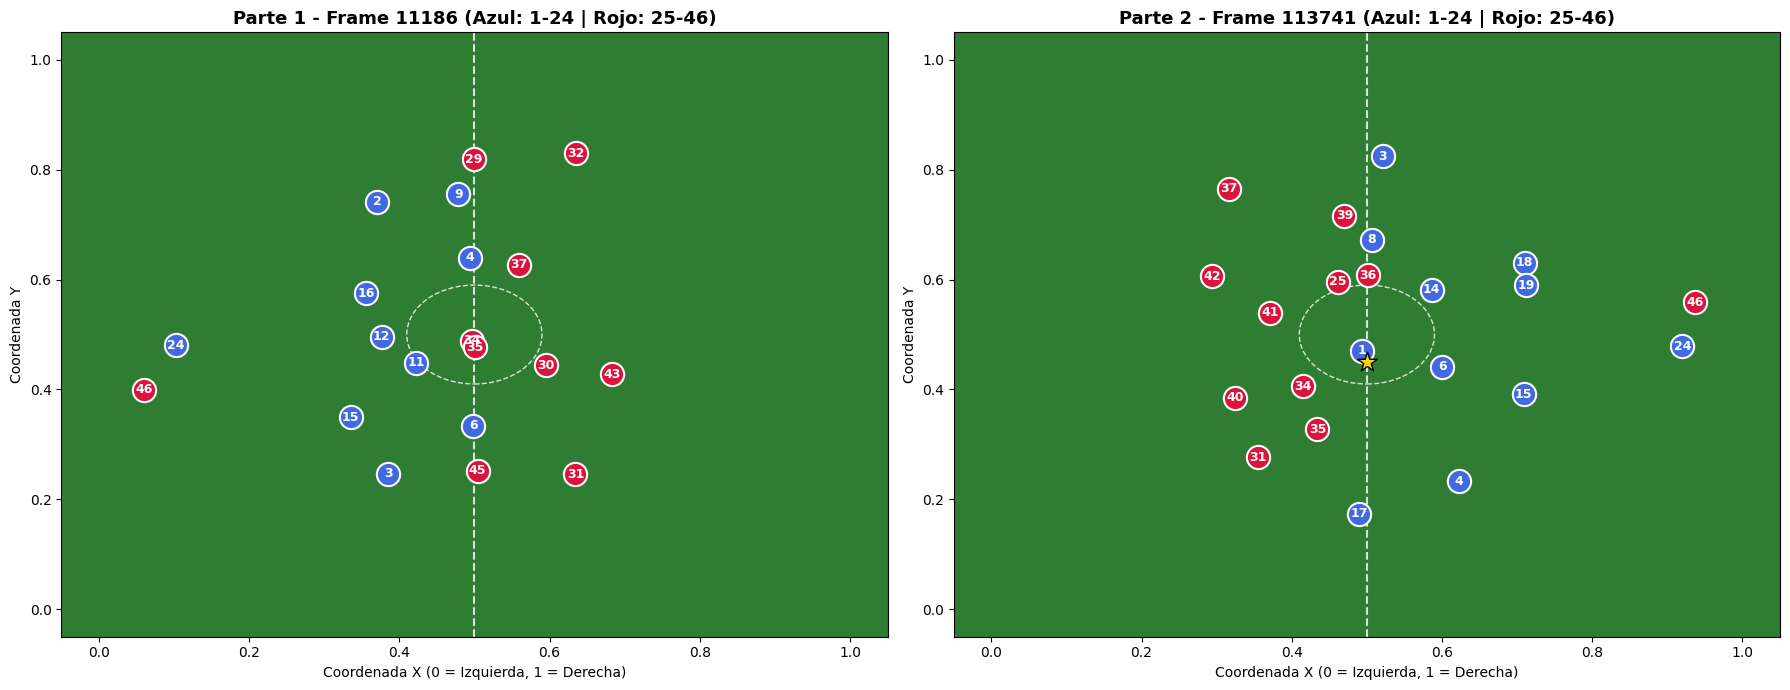

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for idx, (half, (start_frame, _)) in enumerate(real_halves.items()):
    ax = axes[idx]
    row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    
    # Recorrer los 46 posibles jugadores
    for pid in range(1, 47):
        px = row.get(f"{pid}_x", np.nan)
        py = row.get(f"{pid}_y", np.nan)
        
        if pd.notna(px) and pd.notna(py):
            # Color azul para 1-24, rojo para 25-46
            color = "royalblue" if pid <= 24 else "crimson"
            
            # Dibujar el círculo del jugador
            ax.scatter(px, py, c=color, s=280, edgecolors="white", linewidth=1.5, zorder=3)
            
            # Escribir el número del jugador justo encima
            ax.text(
                px, py, str(pid), 
                color="white", fontsize=9, fontweight="bold", 
                ha="center", va="center", zorder=4
            )
            
    # Dibujar la pelota (estrella amarilla)
    if pd.notna(row.get("ball_x")) and pd.notna(row.get("ball_y")):
        ax.scatter(
            row["ball_x"], row["ball_y"], 
            c="gold", s=220, marker="*", edgecolors="black", zorder=5, label="Ball"
        )
    
    # Líneas del campo [0, 1]
    ax.axvline(0.5, color="white", linestyle="--", alpha=0.8)
    circle = plt.Circle((0.5, 0.5), 0.09, color="white", fill=False, linestyle="--", alpha=0.8)
    ax.add_patch(circle)
    
    # Estética del campo
    ax.set_facecolor("#2e7d32")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f"Parte {half} - Frame {int(row['frame_id'])} (Azul: 1-24 | Rojo: 25-46)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Coordenada X (0 = Izquierda, 1 = Derecha)")
    ax.set_ylabel("Coordenada Y")

plt.tight_layout()
plt.show()

Buscando frame real: 121850


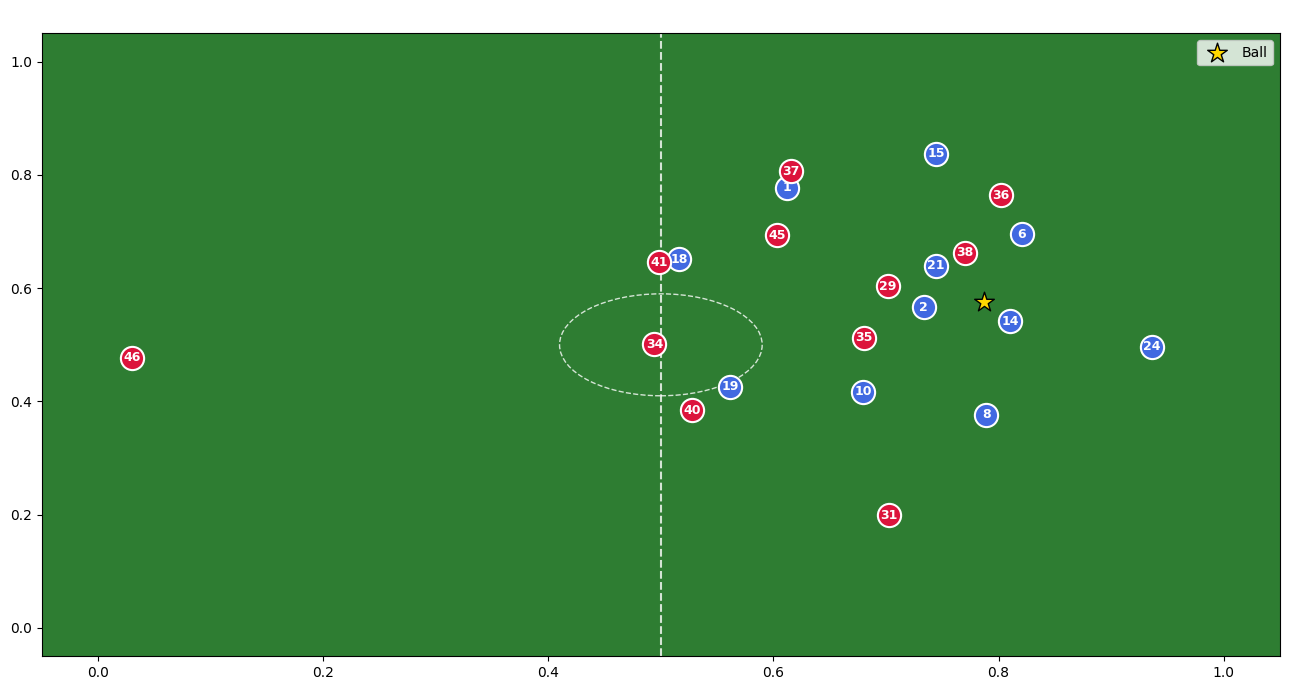

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Calcular el frame real para el minuto 1:21:14 a 25 FPS
hours, minutes, seconds = 1, 21, 14
target_real_frame = (hours * 3600 + minutes * 60 + seconds) * 25

print(f"Buscando frame real: {target_real_frame}")

# 2. Encontrar la fila en el DataFrame (buscando el exacto o el más cercano)
row_match = df[df["frame_id"] == target_real_frame]
if row_match.empty:
  idx_closest = (df["frame_id"] - target_real_frame).abs().idxmin()
  row = df.loc[idx_closest]
  print(
      f"Frame exacto no encontrado. Mostrando el más cercano: ID"
      f" {int(row['frame_id'])}"
  )
else:
  row = row_match.iloc[0]

# 3. Dibujar el campo y los jugadores
fig, ax = plt.subplots(figsize=(13, 7))

HOME_IDS = list(range(1, 25))
AWAY_IDS = list(range(25, 47))

# Pintar jugadores
for pid in range(1, 47):
  px = row.get(f"{pid}_x", np.nan)
  py = row.get(f"{pid}_y", np.nan)

  if pd.notna(px) and pd.notna(py):
    color = "royalblue" if pid <= 24 else "crimson"
    ax.scatter(
        px, py, c=color, s=280, edgecolors="white", linewidth=1.5, zorder=3
    )
    ax.text(
        px,
        py,
        str(pid),
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        zorder=4,
    )

# Pintar la pelota
if pd.notna(row.get("ball_x")) and pd.notna(row.get("ball_y")):
  ax.scatter(
      row["ball_x"],
      row["ball_y"],
      c="gold",
      s=220,
      marker="*",
      edgecolors="black",
      zorder=5,
      label="Ball",
  )

# Geometría básica del campo
ax.axvline(0.5, color="white", linestyle="--", alpha=0.8)
circle = plt.Circle(
    (0.5, 0.5), 0.09, color="white", fill=False, linestyle="--", alpha=0.8
)
ax.add_patch(circle)

ax.set_facecolor("#2e7d32")
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_title(
    f"Minuto 1:21:14 (Frame Real: {int(row['frame_id'])})",
    fontsize=14,
    fontweight="bold",
    color="white",
)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [13]:
# Load Tagging
sys.path.insert(0, os.path.abspath('..'))
import games
print("Cargando Smart Tagging (Eventos)...")
path = games.asset_paths()['smart_tagging']
events_df = sportscode.load(path).to_df()
print(f"-> {len(events_df)} instancias cargadas con éxito.")
display(events_df.head(20))

Cargando Smart Tagging (Eventos)...
-> 638 instancias cargadas con éxito.


,code_id,period_id,timestamp,end_timestamp,code,Team,Type,Half,Max Players in the box,Side,Direction of ball entry
0,1,1,0 days 00:07:23.880000,0 days 00:07:28.880000,SET PIECES,N/A,Kick Off (Start),1st Half,None,None,None
1,2,1,0 days 00:33:05.240000,0 days 00:33:10.240000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
2,3,1,0 days 00:41:20.480000,0 days 00:41:25.480000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
3,4,1,0 days 00:50:18.280000,0 days 00:50:23.280000,SET PIECES,N/A,Kick Off (After Goal),1st Half,None,None,None
4,5,1,0 days 01:15:46.400000,0 days 01:15:51.400000,SET PIECES,N/A,Kick Off (Start),2nd Half,None,None,None
5,6,1,0 days 01:48:40,0 days 01:48:45,SET PIECES,N/A,Kick Off (After Goal),2nd Half,None,None,None
6,7,1,0 days 01:17:41.720000,0 days 01:18:09.400000,PLAYERS IN THE BOX,Barcelona,None,2nd Half,4,None,None
7,8,1,0 days 01:18:42.760000,0 days 01:19:07.040000,PLAYERS IN THE BOX,Barcelona,None,2nd Half,4,None,None
8,9,1,0 days 01:21:23.200000,0 days 01:21:44.600000,PLAYERS IN THE BOX,Barcelona,None,2nd Half,2,None,None
9,10,1,0 days 01:22:46.080000,0 days 01:23:11.160000,PLAYERS IN THE BOX,Barcelona,None,2nd Half,2,None,None


# Progression

In [14]:
import numpy as np
import pandas as pd

# ==========================================
# CONFIGURACIÓN DE VARIABLES
# ==========================================

# Variables generales
FPS = 25               # Frames por segundo
VIDEO_FRAMES = 199319  # Frames totales del video
PITCH_CENTER_X = 0.5   # Cambiar a 52.5 si el campo va de 0 a 105
PITCH_CENTER_Y = 0.5   # Cambiar a 34.0 si el campo va de 0 a 68
SANITY_WINDOW_FRAMES = 75

# Frames de las partes
MATCH_META = {"offsets": {1: 1702057, 2: 1702058},
              "halves": {1: (1713242, 1792708), 2: (1812866, 1892255)},
              "kickoffs": {1: {"minute": 7, "second": 27, "frame": 11}, 2: {"minute": 75, "second": 49, "frame": 16}}}
real_halves = {half: (
        (MATCH_META["kickoffs"][half]["minute"] * 60 + MATCH_META["kickoffs"][half]["second"]) * 25 + MATCH_META["kickoffs"][half]["frame"],
        MATCH_META["halves"][half][1] - MATCH_META["offsets"][half])
    for half in [1, 2]}

# Etiquetas y rangos de jugadores por equipo
HOME_TAG = "H"   
AWAY_TAG = "A"   
HOME_IDS = list(range(1, 25))   # Jugadores del 1 al 24
AWAY_IDS = list(range(25, 47))  # Jugadores del 25 al 46

# Variables threshoold
TH_BALL_SPEED = 0.1
SANITY_WINDOW_FRAMES = 100  # 3 segundos a 25 FPS
SANITY_RATIO = 0.75        # 75% de la ventana
MARGIN_END_FRAMES = 25*15

# Columnas tácticas del CSV
ATTACK_COLUMNS = [
    "progression", "attacking_trend", "build_up", 
    "long_ball", "creating_chances", "players_in_the_box"
]

DEFENSE_COLUMNS = [
    "defending_in_middle_third", "defensive_transition", 
    "defending_in_attacking_third", "defending_in_defensive_third"
]




# ==========================================
# PASO 0: PONER LAS 'X' Y SEPARAR PARTES
# ==========================================
def init_frames_with_X(halves_dict=real_halves, n_video_frames=VIDEO_FRAMES):
    """
    Inicializa el DataFrame de predicciones para todo el vídeo.
    Etiqueta con 'X' los tramos fuera de juego (pre-partido, descanso y post-partido)
    y deja en None los frames correspondientes a la 1ª y 2ª parte.

    Args:
        halves_dict (dict): Diccionario {1: (start_1, end_1), 2: (start_2, end_2)} en frames reales.
        n_video_frames (int): Número total de frames del vídeo.

    Returns:
        pd.DataFrame: DataFrame con columnas ['frame', 'label'].
    """

    # 1. Crear el DataFrame con las dos columnas: 'frame' (0 a n_video_frames - 1) y 'label'
    # Inicializamos todo con "X" por defecto
    df_results = pd.DataFrame({
        "frame": range(n_video_frames),
        "label": "D"
    })
    
    # 2. Dejar vacíos (None) los frames que sí corresponden a la 1ª y 2ª parte
    for half, (start_frame, end_frame) in halves_dict.items():
        df_results.loc[start_frame:end_frame, "label"] = None
        
    return df_results




# ==========================================
# PASO 1: FUNCIÓN DE KICK OFF (START)
# ==========================================

def kick_off(df, start_frame, max_wait_frames=500):
    """
    Analiza el saque de centro al inicio de una parte para determinar hacia dónde
    ataca cada equipo, quién empieza con la posesión y en qué frame se pone el balón en juego.

    Args:
        df (pd.DataFrame): DataFrame con los datos de tracking y velocidades.
        start_frame (int): Frame real en el que comienza la parte.
        max_wait_frames (int, optional): Límite de frames a explorar hasta el golpeo inicial.

    Returns:
        tuple:
            - attack_dir (dict): Dirección de ataque por equipo ({'H': 1/-1, 'A': -1/1}).
            - starting_team (str): Etiqueta del equipo que realiza el saque ('H' o 'A').
            - play_start_frame (int): Frame exacto en el que el balón empieza a moverse.
    """

    # 0. Localizar el frame de inicio en el df
    row_mask = df["frame_id"] == start_frame
    if row_mask.any():
        row = df.loc[row_mask].iloc[0]
    else:
        # Por si falta algún frame exacto, cogemos el primero disponible a partir de start_frame
        row = df.loc[df["frame_id"] >= start_frame].iloc[0]
    # Columnas X de cada equipo
    home_x_cols = [f"{i}_x" for i in HOME_IDS if f"{i}_x" in df.columns]
    away_x_cols = [f"{i}_x" for i in AWAY_IDS if f"{i}_x" in df.columns]


    # 1. Detectar donde ataca cada equipo (Posición jugadores a banda y banda)
    home_median_x = row[home_x_cols].median()
    away_median_x = row[away_x_cols].median()
    # Si la mediana de X es menor, están en el campo izquierdo (X < 0.5) y atacan hacia la derecha (+1)
    if home_median_x < away_median_x:
        attack_dir = {HOME_TAG: 1, AWAY_TAG: -1}
    else:
        attack_dir = {HOME_TAG: -1, AWAY_TAG: 1}

  
    # 2. Definir quien empieza con la posesión (jugador mas cercano a 0.5, 0.5)
    player_distances = []
    for pid in HOME_IDS + AWAY_IDS:
        px = row.get(f"{pid}_x", np.nan)
        py = row.get(f"{pid}_y", np.nan)
        if pd.notna(px) and pd.notna(py):
            dist = np.hypot(px - PITCH_CENTER_X, py - PITCH_CENTER_Y)
            team = HOME_TAG if pid in HOME_IDS else AWAY_TAG
            player_distances.append((dist, team, pid))
    # Ordenar por distancia al centro y coger el más cercano
    player_distances.sort(key=lambda x: x[0])
    starting_team = [item[1] for item in player_distances[:1]]

    # 3. Detectar cuando empieza a jugarse el balón (Cuando la pelota coge velocidad)
    window = df[
        (df["frame_id"] >= start_frame) & 
        (df["frame_id"] <= start_frame + max_wait_frames)
    ]
    dist_ball_center = np.hypot(
        window["ball_x"] - PITCH_CENTER_X, 
        window["ball_y"] - PITCH_CENTER_Y
    )
    # La pelota se juega cuando supera el umbral de velocidad 
    moving_mask = (window["ball_speed"] > TH_BALL_SPEED) 
    moving_frames = window.loc[moving_mask, "frame_id"]

    if not moving_frames.empty:
        play_start_frame = int(moving_frames.iloc[0])
    else:
        play_start_frame = start_frame

    return attack_dir, starting_team, play_start_frame




# ============================================
# PASO 2: ESTUDIAR Y DEFINIR JUEGO PROGRESIVO
# ============================================


# FUNCIÓN: MAPEA EL EQUIPO CON LAS LABELS

def map_team_str_to_tag(val):
    """
    Traduce el string del dataset a etiqueta corta:
    - Si contiene 'ba'/'Ba' -> 'H'
    - Si contiene 'at'/'At' -> 'A'
    """
    if pd.isna(val):
        return None
    val_str = str(val)
    if "ba" in val_str.lower():
        return HOME_TAG
    elif "at" in val_str.lower():
        return AWAY_TAG
    return None


# FUNCIÓN: CALCULAR JUGADOR MÁS CERCANO POR FRAME

def compute_closest_player_per_frame(df):
    """
    Recorre todas las filas del DataFrame y calcula en cada frame 
    qué equipo tiene al jugador más cercano a la pelota.
    Devuelve la columna 'closest_team' con valores 'H' o 'A'.
    """
    n_rows = len(df)
    ball_x = df["ball_x"].to_numpy()
    ball_y = df["ball_y"].to_numpy()
    
    closest_team_arr = []
    
    # Pre-extraer coordenadas en arrays de numpy para que vaya rapidísimo
    home_x = [df.get(f"{i}_x", pd.Series([np.nan]*n_rows)).to_numpy() for i in range(1, 25)]
    home_y = [df.get(f"{i}_y", pd.Series([np.nan]*n_rows)).to_numpy() for i in range(1, 25)]
    
    away_x = [df.get(f"{i}_x", pd.Series([np.nan]*n_rows)).to_numpy() for i in range(25, 47)]
    away_y = [df.get(f"{i}_y", pd.Series([np.nan]*n_rows)).to_numpy() for i in range(25, 47)]
    
    for idx in range(n_rows):
        bx, by = ball_x[idx], ball_y[idx]
        
        # Si no hay coordenadas válidas de pelota en este frame, dejamos NaN
        if pd.isna(bx) or pd.isna(by):
            closest_team_arr.append(np.nan)
            continue
            
        min_dist = float('inf')
        closest_t = None
        
        # Buscar el jugador más cercano en el equipo Home (1-24)
        for hx_arr, hy_arr in zip(home_x, home_y):
            px, py = hx_arr[idx], hy_arr[idx]
            if not pd.isna(px) and not pd.isna(py):
                d = np.hypot(px - bx, py - by)
                if d < min_dist:
                    min_dist = d
                    closest_t = "H"
                    
        # Buscar el jugador más cercano en el equipo Away (25-46)
        for ax_arr, ay_arr in zip(away_x, away_y):
            px, py = ax_arr[idx], hy_arr[idx] if False else ax_arr[idx] # (seguridad de arrays)
            px, py = ax_arr[idx], ay_arr[idx]
            if not pd.isna(px) and not pd.isna(py):
                d = np.hypot(px - bx, py - by)
                if d < min_dist:
                    min_dist = d
                    closest_t = "A"
                    
        closest_team_arr.append(closest_t)
        
    df["closest_team"] = closest_team_arr
    return df


# FUNCIÓN PRINCIPAL: SANITY CHECK DE 3 NIVELES

def run_final_sanity_check(df, df_results, start_frame, end_frame, initial_team):
    """
    Jerarquía de 3 niveles con conversión robusta a numérico (evita errores de tipo object):
      1. Eventos tácticos del CSV (convirtiendo valores de object a numérico de forma segura).
      2. Jugador más cercano analizando los 75 frames anteriores.
      3. Fallback: Mantener el último equipo con posesión conocida.
    """
    current_team = initial_team
    
    if "closest_team" not in df.columns:
        df = compute_closest_player_per_frame(df)
        
    mask_part = df["frame_id"].between(start_frame, end_frame)
    df_part = df[mask_part].sort_values("frame_id")
    
    frames_list = df_part["frame_id"].to_numpy()
    closest_teams = df_part["closest_team"].to_numpy()
    row_dicts = df_part.to_dict("records")
    
    n = len(frames_list)
    i = 0
    
    while i < n:
        current_frame = int(frames_list[i])
        row_data = row_dicts[i]
        
        ball_is_valid = pd.notna(row_data.get("ball_x")) and pd.notna(row_data.get("ball_y"))
        
        # ---------------------------------------------------------
        # NIVEL 1: Eventos tácticos (con conversión segura a numérico)
        # ---------------------------------------------------------
        tactical_forced_team = None
        
        # Comprobar ataques
        for col in ATTACK_COLUMNS:
            val_raw = row_data.get(col, 0)
            # Convertir de object/string a numérico de forma segura
            val = pd.to_numeric(val_raw, errors='coerce')
            if pd.isna(val):
                val = 0
                
            # Regla especial para players_in_the_box: ignorar si es 1 o 2 (debe ser > 2)
            if col == "players_in_the_box":
                is_active = (val > 2)
            else:
                is_active = (val == 1)
                
            if is_active:
                # Look-ahead contando frames mientras siga activo
                remaining_frames = 0
                k = i
                while k < n:
                    k_val_raw = row_dicts[k].get(col, 0)
                    k_val = pd.to_numeric(k_val_raw, errors='coerce')
                    if pd.isna(k_val):
                        k_val = 0
                        
                    if col == "players_in_the_box":
                        if k_val <= 2:
                            break
                    else:
                        if k_val != 1:
                            break
                    remaining_frames += 1
                    k += 1
                
                # Si estamos a más de 15 segundos (375 frames) del final del evento, lo obedecemos
                if remaining_frames > MARGIN_END_FRAMES:
                    team_col = f"{col}_team"
                    if team_col in row_data:
                        mapped = map_team_str_to_tag(row_data[team_col])
                        if mapped is not None:
                            tactical_forced_team = mapped
                            break
                    
        # Comprobar defensas
        if tactical_forced_team is None:
            for col in DEFENSE_COLUMNS:
                val_raw = row_data.get(col, 0)
                val = pd.to_numeric(val_raw, errors='coerce')
                if pd.isna(val):
                    val = 0
                    
                if val == 1:
                    remaining_frames = 0
                    k = i
                    while k < n:
                        k_val_raw = row_dicts[k].get(col, 0)
                        k_val = pd.to_numeric(k_val_raw, errors='coerce')
                        if pd.isna(k_val):
                            k_val = 0
                        if k_val != 1:
                            break
                        remaining_frames += 1
                        k += 1
                    
                    if remaining_frames > MARGIN_END_FRAMES:
                        team_col = f"{col}_team"
                        if team_col in row_data:
                            def_tag = map_team_str_to_tag(row_data[team_col])
                            if def_tag is not None:
                                tactical_forced_team = AWAY_TAG if def_tag == HOME_TAG else HOME_TAG
                                break
                        
        if tactical_forced_team is not None:
            current_team = tactical_forced_team
            
        else:
            # ---------------------------------------------------------
            # NIVEL 2: Ventana de los 75 frames ANTERIORES (Geometría)
            # ---------------------------------------------------------
            if ball_is_valid and i >= SANITY_WINDOW_FRAMES:
                window_teams = closest_teams[i - SANITY_WINDOW_FRAMES : i]
                window_teams_clean = window_teams[pd.notna(window_teams)]
                
                if len(window_teams_clean) > 0:
                    rival_team = AWAY_TAG if current_team == HOME_TAG else HOME_TAG
                    rival_ratio = np.mean(window_teams_clean == rival_team)
                    
                    if rival_ratio >= SANITY_RATIO:
                        current_team = rival_team
                        
            # ---------------------------------------------------------
            # NIVEL 3: Fallback (Mantiene el `current_team` anterior)
            # ---------------------------------------------------------
            pass
        
        # Asignar la posesión resuelta al frame actual
        df_results.loc[current_frame, "label"] = current_team
        i += 1
        
    return df_results

In [15]:
# 1. Definir los límites de la prueba
start_frame_p1 = int(real_halves[1][0]) # Frame de inicio oficial (kickoff)
FPS = 25
end_frame_test = 190197

print(f"--- INICIANDO TEST (1ª Parte: 10 primeros minutos) ---")
print(f"Frame de inicio (Kick-off): {start_frame_p1}")
print(f"Frame de fin del test     : {end_frame_test}")

# 2. Inicializar un DataFrame de resultados limpio solo para esta prueba)
df_results = init_frames_with_X(real_halves, VIDEO_FRAMES)
print("Conteo tras Paso 0 (solo X y None):")
print(df_results["label"].value_counts(dropna=False))
print("-" * 50)

# 3. Obtener los datos de inicio del kick-off para la Parte 1
attack_dir, starting_team, play_start_frame = kick_off(df, start_frame_p1)
play_start_frame = int(play_start_frame)

print(f"Equipo que saca en el kickoff: {starting_team}")
print(f"Pelota en juego oficial en el frame: {play_start_frame}")

# 4. Rellenar con 'D' (Dead Ball) el tramo previo al saque si lo hubiera
if play_start_frame > start_frame_p1:
    df_results.loc[start_frame_p1 : play_start_frame - 1, "label"] = "D"

# 5. Asegurarnos de que el cálculo del jugador más cercano está hecho
if "closest_team" not in df.columns:
    print("Calculando jugador más cercano para todo el dataset...")
    df = compute_closest_player_per_frame(df)

# 6. Ejecutar la función de sanity check limitada a estos 10 minutos
print("Ejecutando 'run_final_sanity_check' para el test...")
df_results = run_final_sanity_check(
    df=df,
    df_results=df_results,
    start_frame=play_start_frame,
    end_frame=end_frame_test,
    initial_team=starting_team
)

# 7. Mostrar resultados y estadísticas del test
print("\n--- RESULTADOS DEL TEST (10 primeros min) ---")
mask_test = df["frame_id"].between(start_frame_p1, end_frame_test)
conteo_etiquetas = df_results.loc[df[mask_test].index, "label"].value_counts()
print(conteo_etiquetas)

--- INICIANDO TEST (1ª Parte: 10 primeros minutos) ---
Frame de inicio (Kick-off): 11186
Frame de fin del test     : 190197
Conteo tras Paso 0 (solo X y None):
label
None    155923
D        43396
Name: count, dtype: int64
--------------------------------------------------
Equipo que saca en el kickoff: ['A']
Pelota en juego oficial en el frame: 11189
Calculando jugador más cercano para todo el dataset...
Ejecutando 'run_final_sanity_check' para el test...

--- RESULTADOS DEL TEST (10 primeros min) ---
label
H      101109
A       77884
[A]        15
D           4
Name: count, dtype: int64


In [16]:
# 8. SEGUIMIENTO DETALLADO CADA SEGUNDO (25 frames) con TIPO DE EVENTO
print("\n--- SEGUIMIENTO DETALLADO DE POSESIÓN Y EVENTOS (CADA SEGUNDO) ---")
print(f"{'FRAME':<10} | {'TIEMPO':<10} | {'POSESIÓN':<10} | {'BALÓN OK':<10} | {'TIPO DE EVENTO':<25} | {'ATAQUE EQUIPO':<15} | {'DEFENSA EQUIPO':<15}")
print("-" * 102)

# Recorrer el rango de los 10 minutos saltando de 25 en 25 frames
for f_id in range(start_frame_p1, end_frame_test + 1, 25):
    # Buscar la fila correspondiente en el dataframe principal usando el frame_id
    row_match = df[df["frame_id"] == f_id]
    
    if not row_match.empty:
        idx = row_match.index[0]
        row_data = row_match.iloc[0]
        
        # 1. Posesión asignada
        possession = df_results.loc[idx, "label"] if idx in df_results.index else "-"
        
        # 2. Calcular tiempo en formato Minutos:Segundos desde el inicio del test
        frames_elapsed = f_id
        total_seconds = frames_elapsed / FPS
        minutes = int(total_seconds // 60)
        seconds = int(total_seconds % 60)
        time_str = f"{minutes:02d}:{seconds:02d}"
        
        # 3. Comprobar si hay posición de balón válida
        has_ball = "Sí" if (pd.notna(row_data.get("ball_x")) and pd.notna(row_data.get("ball_y"))) else "No"
        
        # 4. Detectar el tipo de evento activo y qué equipo interviene
        active_event_type = "-"
        active_attack_team = "-"
        active_defense_team = "-"
        
        # Buscar en columnas de ataque
        for col in ATTACK_COLUMNS:
            if col in row_data and row_data[col] == 1:
                active_event_type = col
                team_col = f"{col}_team"
                if team_col in row_data:
                    active_attack_team = str(row_data[team_col])
                break
                
        # Si no hay ataque, buscar en columnas de defensa
        if active_event_type == "-":
            for col in DEFENSE_COLUMNS:
                if col in row_data and row_data[col] == 1:
                    active_event_type = col
                    team_col = f"{col}_team"
                    if team_col in row_data:
                        active_defense_team = str(row_data[team_col])
                    break
        
        print(f"{f_id:<10} | {time_str:<10} | {possession:<10} | {has_ball:<10} | {active_event_type:<25} | {active_attack_team:<15} | {active_defense_team:<15}")


--- SEGUIMIENTO DETALLADO DE POSESIÓN Y EVENTOS (CADA SEGUNDO) ---
FRAME      | TIEMPO     | POSESIÓN   | BALÓN OK   | TIPO DE EVENTO            | ATAQUE EQUIPO   | DEFENSA EQUIPO 
------------------------------------------------------------------------------------------------------
11186      | 07:27      | D          | No         | long_ball                 | Atletic Club    | -              
11211      | 07:28      | A          | Sí         | progression               | Atletic Club    | -              
11236      | 07:29      | A          | Sí         | progression               | Atletic Club    | -              
11261      | 07:30      | A          | Sí         | progression               | Atletic Club    | -              
11286      | 07:31      | A          | Sí         | progression               | Atletic Club    | -              
11311      | 07:32      | A          | Sí         | progression               | Atletic Club    | -              
11336      | 07:33      | A    

# Printing

In [ ]:
# 1. Clean types and formatting
df_results["frame"] = df_results["frame"].astype(int)
df_results["label"] = (
    df_results["label"]
    .apply(lambda x: x[0] if isinstance(x, list) and len(x) > 0 else x)
    .astype(str)
    .str.strip("[]'\" ")
)

# 2. Pre-export validation checks
assert list(df_results.columns) == ["frame", "label"], f"Invalid columns: {list(df_results.columns)}"
assert len(df_results) == VIDEO_FRAMES, f"Expected {VIDEO_FRAMES} rows, got {len(df_results)}"
assert df_results["frame"].is_monotonic_increasing and df_results["frame"].nunique() == len(df_results), "Frames are not strictly sequential/unique"
assert not df_results.isna().any().any(), "DataFrame contains NaN/null values"

valid_labels = {"H", "A", "D", "X"}
invalid_mask = ~df_results["label"].isin(valid_labels)
assert not invalid_mask.any(), f"Invalid labels found: {df_results.loc[invalid_mask, 'label'].unique()} at frames {df_results.loc[invalid_mask, 'frame'].tolist()[:10]}"

# 3. Inspect and save once all checks pass
print("Validation passed! Label distribution:")
print(df_results["label"].value_counts())
print("\nPreview:")
print(df_results.head())

sys.path.insert(0, os.path.abspath('..'))
df_results.to_csv("../evaluation/results/trial.csv", index=False)
print("\nSaved valid file to trial.csv")

Validation passed! Label distribution:
label
H    101109
A     77900
D     20310
Name: count, dtype: int64

Preview:
   frame label
0      0     D
1      1     D
2      2     D
3      3     D
4      4     D

Saved valid file to trial.csv


sp_reason
ball missing    33905
ball out         3361
stopped          2790
Name: count, dtype: int64


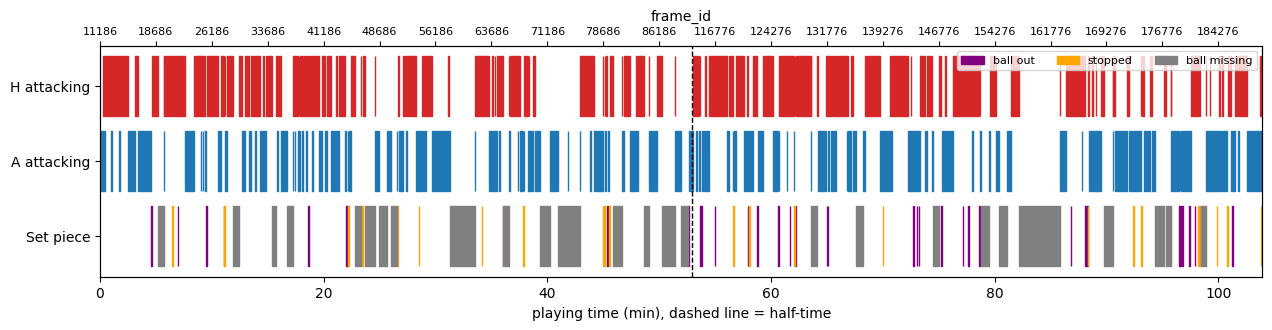

In [ ]:
BALL_STOP = 0.1       # ball_speed below this = ball stopped (same value as TH_BALL_SPEED)
PLAYER_STOP = 1.0     # median player speed below this (m/s) = players standing
MIN_OUT_S, MIN_STOP_S, MIN_MISSING_S = 1, 3, 25   # seconds a condition must last to count
HOME_COLOUR = "#d62728"
AWAY_COLOUR = "#1f77b4"

def _long_runs(mask, min_len):
    """Keep only the runs of True that last at least min_len frames."""
    edges = np.flatnonzero(np.diff(np.r_[0, mask.astype(np.int8), 0]))
    out = np.zeros(len(mask), dtype=bool)
    for s, e in zip(edges[::2], edges[1::2]):
        if e - s >= min_len:
            out[s:e] = True
    return out


def detect_set_pieces(df, halves=None):
    """One row per in-play frame: frame_id and sp_reason in {'ball out', 'stopped', 'ball missing', None}.
    'ball missing' only counts frames not already claimed by the other two rules."""
    halves = halves or real_halves
    speed_cols = [f"{i}_s" for i in HOME_IDS + AWAY_IDS]
    parts = []
    for s, e in halves.values():
        d = df[(df["frame_id"] >= s) & (df["frame_id"] <= e)]
        out = ((d["ball_x"] < 0) | (d["ball_x"] > 1) | (d["ball_y"] < 0) | (d["ball_y"] > 1)).to_numpy()
        stop = ((d["ball_speed"] < BALL_STOP) & (d[speed_cols].median(axis=1) < PLAYER_STOP)).to_numpy()
        out_l = _long_runs(out, MIN_OUT_S * FPS)
        stop_l = _long_runs(stop, MIN_STOP_S * FPS)
        miss_l = _long_runs(d["ball_x"].isna().to_numpy() & ~out_l & ~stop_l, MIN_MISSING_S * FPS)
        reason = np.full(len(d), None, dtype=object)
        reason[miss_l] = "ball missing"
        reason[stop_l] = "stopped"          # priority: ball out > stopped > ball missing
        reason[out_l] = "ball out"
        parts.append(pd.DataFrame({"frame_id": d["frame_id"].to_numpy(), "sp_reason": reason}))
    return pd.concat(parts, ignore_index=True)


def add_set_pieces(df_results, sp):
    """Add an 'sp_reason' column to df_results (the frame/label table). The H/A labels are not touched;
    the plots simply treat frames with an sp_reason as 'nobody has possession'."""
    df_results = df_results.copy()
    df_results["sp_reason"] = df_results["frame"].map(sp.set_index("frame_id")["sp_reason"])
    return df_results


def plot_match_timeline(df_results, halves=None, ax=None):
    """Whole-match timeline of who attacks (label H/A) and when a set piece happens (sp_reason).
    x axis = playing time in minutes (half-time removed); extra top axis = frame_id."""
    halves = halves or real_halves
    (s1, e1), (s2, e2) = halves[1], halves[2]
    d = pd.concat([df_results[(df_results["frame"] >= s) & (df_results["frame"] <= e)]
                   for s, e in halves.values()])
    f = d["frame"].to_numpy()
    len1 = (e1 - s1) / FPS / 60                                  # length of the first half (min)
    x = np.where(f <= e1, (f - s1) / FPS / 60, len1 + (f - s2) / FPS / 60)
    dt = 1 / FPS / 60
    sp = d["sp_reason"] if "sp_reason" in d else pd.Series(None, index=d.index, dtype=object)
    free = sp.isna()                                             # frames that are not a set piece

    rows = [(f"{HOME_TAG} attacking", (d["label"] == HOME_TAG) & free, HOME_COLOUR, 3, None),
            (f"{AWAY_TAG} attacking", (d["label"] == AWAY_TAG) & free, AWAY_COLOUR, 2, None)]
    rows += [("Set piece", sp == r, c, 1, r) for r, c in
             [("ball out", "purple"), ("stopped", "orange"), ("ball missing", "grey")]]
    ax = ax or plt.subplots(figsize=(15, 3))[1]
    for name, m, colour, y, label in rows:
        m = m.to_numpy(dtype=bool)
        edges = np.flatnonzero(np.diff(np.r_[0, m.astype(np.int8), 0]))
        spans = [(x[s], x[e - 1] - x[s] + dt) for s, e in zip(edges[::2], edges[1::2])]
        ax.broken_barh(spans, (y - 0.4, 0.8), color=colour, label=label)
    ax.axvline(len1, color="black", ls="--", lw=1)
    ax.set_yticks([1, 2, 3])
    ax.set_yticklabels(["Set piece", f"{AWAY_TAG} attacking", f"{HOME_TAG} attacking"])
    ax.set_xlim(0, x.max())
    ax.set_xlabel("playing time (min), dashed line = half-time")
    ax.legend(loc="upper right", ncol=3, fontsize=8)

    ticks = np.arange(0, x.max(), 5)                             # top axis: frame_id every 5 min
    frames = [int(s1 + m * 60 * FPS) if m <= len1 else int(s2 + (m - len1) * 60 * FPS) for m in ticks]
    top = ax.twiny()
    top.set_xlim(ax.get_xlim())
    top.set_xticks(ticks)
    top.set_xticklabels(frames, fontsize=8)
    top.set_xlabel("frame_id")
    return ax


# Usage (after your algorithm has filled df_results with H / A):
sp = detect_set_pieces(df)
print(sp["sp_reason"].value_counts())
df_results = add_set_pieces(df_results, sp)
plot_match_timeline(df_results); plt.show()

MovieWriter ffmpeg unavailable; using Pillow instead.


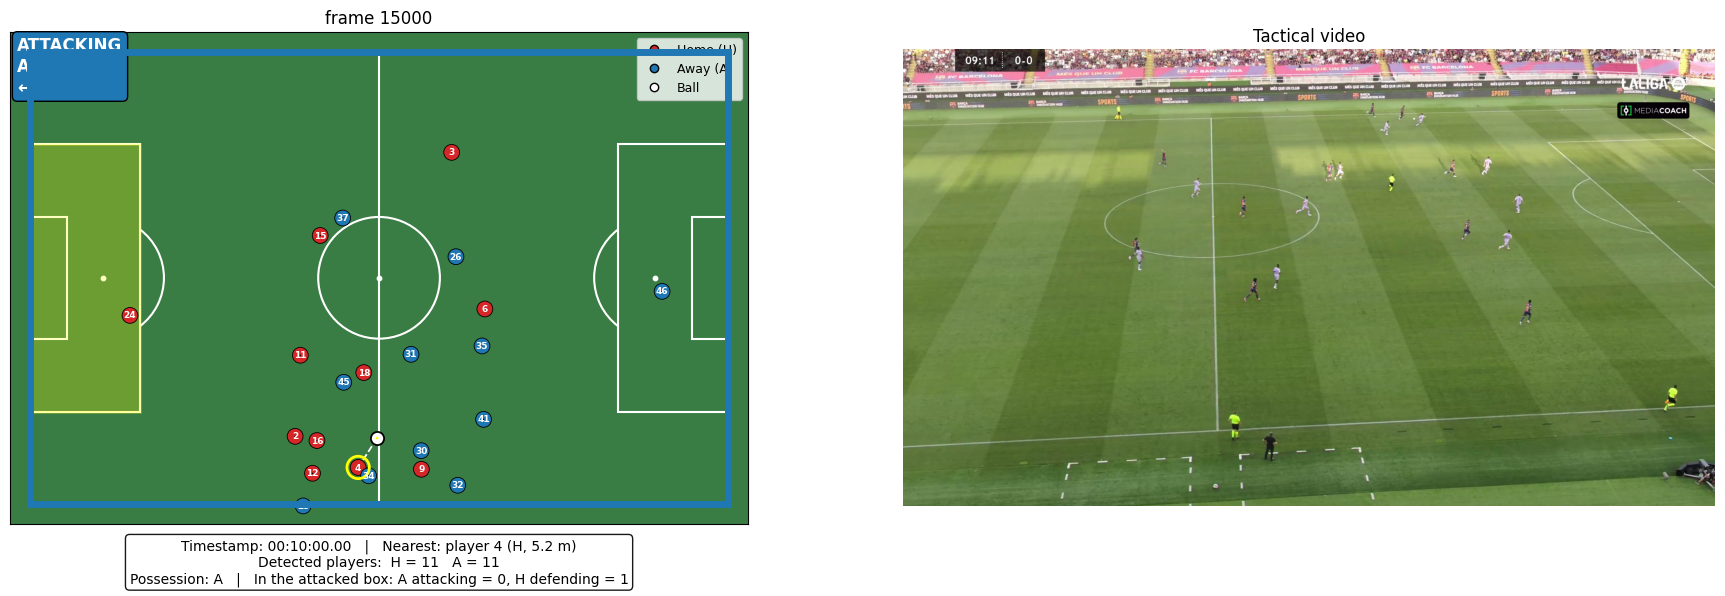

In [ ]:
BOX_DEPTH, BOX_HALF_WIDTH = 16.5, 20.16      # penalty area (m)
PITCH_LENGTH, PITCH_WIDTH = 105, 68          # pitch (m)
ARROW_SCALE, BALL_ARROW_SCALE = 0.5, 1.5     # velocity arrows (m/s) -> pixels
BALL_COLOUR = "white"
PITCH_COLOUR = "#3a7d44"
from matplotlib.patches import Rectangle, Circle, Arc
from matplotlib.lines import Line2D
# ==========================================
# PITCH
# ==========================================
def draw_pitch(ax=None, length=PITCH_LENGTH, width=PITCH_WIDTH):
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 8))
    ax.set_facecolor(PITCH_COLOUR)
    line = dict(color="white", lw=1.5, zorder=1)

    ax.add_patch(Rectangle((0, 0), length, width, fill=False, **line))
    ax.plot([length / 2] * 2, [0, width], **line)
    ax.add_patch(Circle((length / 2, width / 2), 9.15, fill=False, **line))
    ax.scatter(length / 2, width / 2, s=10, color="white", zorder=1)

    for x0, sign in [(0, 1), (length, -1)]:
        # penalty area (16.5 x 40.32), goal area (5.5 x 18.32)
        ax.add_patch(Rectangle((x0 if sign == 1 else x0 - 16.5, width / 2 - 20.16),
                               16.5, 40.32, fill=False, **line))
        ax.add_patch(Rectangle((x0 if sign == 1 else x0 - 5.5, width / 2 - 9.16),
                               5.5, 18.32, fill=False, **line))
        ax.scatter(x0 + sign * 11, width / 2, s=10, color="white", zorder=1)
        ax.add_patch(Arc((x0 + sign * 11, width / 2), 18.3, 18.3,
                         theta1=-53 if sign == 1 else 127,
                         theta2=53 if sign == 1 else 233, **line))

    ax.set_xlim(-3, length + 3)
    ax.set_ylim(-3, width + 3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


# ==========================================
# HELPERS
# ==========================================
def _get_frame_row(df, frame_id):
    """Return the row for frame_id (or the first available frame after it)."""
    mask = df["frame_id"] == frame_id
    if mask.any():
        return df.loc[mask].iloc[0]
    later = df.loc[df["frame_id"] >= frame_id]
    if later.empty:
        raise ValueError(f"frame_id {frame_id} not found")
    return later.iloc[0]


def _fmt_timestamp(ts):
    """'0 days 00:07:27.440000' -> '00:07:27.44' (works for Timedelta or str)."""
    try:
        ts = pd.Timedelta(ts)
        total = ts.total_seconds()
        h, rem = divmod(total, 3600)
        m, s = divmod(rem, 60)
        return f"{int(h):02d}:{int(m):02d}:{s:05.2f}"
    except Exception:
        return str(ts)


def _players_in_frame(row):
    """List of (player_id, team_tag, x, y, vx, vy) for every tracked player (metres)."""
    players = []
    for pid in HOME_IDS + AWAY_IDS:
        x, y = row.get(f"{pid}_x", np.nan), row.get(f"{pid}_y", np.nan)
        if pd.isna(x) or pd.isna(y):
            continue
        vx = row.get(f"{pid}_x_vel", np.nan)
        vy = row.get(f"{pid}_y_vel", np.nan)
        team = HOME_TAG if pid in HOME_IDS else AWAY_TAG
        players.append((pid, team, x * PITCH_LENGTH, y * PITCH_WIDTH,
                        0.0 if pd.isna(vx) else vx, 0.0 if pd.isna(vy) else vy))
    return players



def animate_frames(df, start_frame, end_frame, labels=None, attack_dir=None,
                   step=1, save_path=None, close_fig=False, video_path=None, video_offset=0):
    """Animate a span of tracking frames.

    labels:     df_results (frame / label / optional sp_reason). None -> no possession info.
    attack_dir: {1: {"H": 1, "A": -1}, 2: {...}} (+1 = attacks towards x = 105). None -> kick_off().
    video_path: tactical .mp4 shown to the right of the pitch (needs `pip install opencv-python`).
                Video frame shown = frame_id + video_offset (try -1 / +1 if it looks one frame off).
    Shows: detected players per team, team in possession (label), attackers / defenders inside the
    attacked box, and a red banner while sp_reason is set (nobody has possession).

    Script:   animate_frames(df, 145000, 145250, labels=df_results, step=5, save_path="clip.gif")
    Notebook: HTML(animate_frames(..., close_fig=True).to_jshtml())
    """
    from matplotlib.animation import FuncAnimation

    L, W = PITCH_LENGTH, PITCH_WIDTH
    ids = HOME_IDS + AWAY_IDS
    n_home = len(HOME_IDS)
    is_home = np.arange(len(ids)) < n_home

    sub = df[(df["frame_id"] >= start_frame) & (df["frame_id"] <= end_frame)].iloc[::step]
    sub = sub.reset_index(drop=True)
    n_frames = len(sub)
    if n_frames == 0:
        raise ValueError("No frames between start_frame and end_frame")

    def arr(cols):
        return sub.reindex(columns=cols).to_numpy(dtype=float)

    PX = arr([f"{i}_x" for i in ids]) * L
    PY = arr([f"{i}_y" for i in ids]) * W
    PVX = np.nan_to_num(arr([f"{i}_x_vel" for i in ids])) * ARROW_SCALE
    PVY = np.nan_to_num(arr([f"{i}_y_vel" for i in ids])) * ARROW_SCALE
    BX = arr(["ball_x"])[:, 0] * L
    BY = arr(["ball_y"])[:, 0] * W
    BVX = np.nan_to_num(arr(["ball_x_vel"])[:, 0]) * BALL_ARROW_SCALE
    BVY = np.nan_to_num(arr(["ball_y_vel"])[:, 0]) * BALL_ARROW_SCALE
    timestamps = sub["timestamp"].to_numpy() if "timestamp" in sub else [""] * n_frames
    frame_ids = sub["frame_id"].to_numpy()
    det_home = np.isfinite(PX[:, :n_home]).sum(axis=1)
    det_away = np.isfinite(PX[:, n_home:]).sum(axis=1)

    # labels aligned to these frames
    poss_arr = sp_arr = None
    if labels is not None:
        lab = labels.drop_duplicates("frame").set_index("frame")
        poss_arr = lab["label"].reindex(frame_ids).to_numpy(dtype=object)
        sp_arr = (lab["sp_reason"].reindex(frame_ids).to_numpy(dtype=object) if "sp_reason" in lab
                  else np.full(n_frames, None, dtype=object))
        if attack_dir is None:
            attack_dir = {h: kick_off(df, real_halves[h][0])[0] for h in (1, 2)}
    second_half_start = real_halves[2][0]

    # ---- artists
    if video_path:
        import cv2
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            raise FileNotFoundError(video_path)
        if abs(cap.get(cv2.CAP_PROP_FPS) - FPS) > 0.5:
            print(f"warning: video fps = {cap.get(cv2.CAP_PROP_FPS):.2f}, tracking fps = {FPS}")
        fig, (ax, vax) = plt.subplots(1, 2, figsize=(22, 8), gridspec_kw={"width_ratios": [1, 1.1]})
        vax.axis("off")
        vax.set_title("Tactical video")
        vim = vax.imshow(np.zeros((9, 16, 3), dtype=np.uint8))
        vpos = [None]                      # index of the next frame the video reader will return
    else:
        fig, ax = plt.subplots(figsize=(12, 8))
        fig.subplots_adjust(right=0.88)
    draw_pitch(ax)
    ax.invert_yaxis()
    colours = [HOME_COLOUR] * n_home + [AWAY_COLOUR] * (len(ids) - n_home)
    players = ax.scatter(PX[0], PY[0], s=130, c=colours, edgecolors="black", linewidths=0.6, zorder=3)
    quiv = ax.quiver(PX[0], PY[0], PVX[0], PVY[0], angles="xy", scale_units="xy", scale=1,
                     width=0.002, color="black", zorder=4)
    texts = [ax.text(0, 0, str(pid), ha="center", va="center", fontsize=6.5,
                     color="white", weight="bold", zorder=5) for pid in ids]
    ball = ax.scatter([], [], s=90, color=BALL_COLOUR, edgecolors="black", linewidths=1.3, zorder=6)
    ball_arrow = ax.quiver([0], [0], [0], [0], angles="xy", scale_units="xy", scale=1,
                           width=0.004, color="yellow", zorder=6)
    near_line, = ax.plot([], [], color="white", ls="--", lw=1.3, zorder=2)
    near_ring = ax.scatter([], [], s=260, facecolors="none", edgecolors="yellow", linewidths=2, zorder=4)
    box = Rectangle((0, W / 2 - BOX_HALF_WIDTH), BOX_DEPTH, 2 * BOX_HALF_WIDTH, facecolor="yellow",
                    alpha=0.25, edgecolor="yellow", lw=2, zorder=1, visible=False)
    border = Rectangle((0, 0), L, W, fill=False, lw=5, zorder=7, visible=False)
    ax.add_patch(box)
    ax.add_patch(border)
    title = ax.set_title("")
    info = ax.text(0.5, -0.03, "", transform=ax.transAxes, ha="center", va="top", fontsize=10,
                   bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))
    lx, ly, lva = (0.01, 0.99, "top") if video_path else (1.015, 0.5, "center")   # video sits on the right
    att_label = ax.text(lx, ly, "", transform=ax.transAxes, ha="left", va=lva, fontsize=12,
                        weight="bold", color="white", bbox=dict(boxstyle="round", facecolor="grey"))
    att_label.set_visible(labels is not None)
    banner = ax.text(0.5, 0.93, "", transform=ax.transAxes, ha="center", va="center", fontsize=16,
                     weight="bold", color="white", zorder=10, visible=False,
                     bbox=dict(boxstyle="round", facecolor="red", edgecolor="black"))
    ax.legend(handles=[
        Line2D([], [], marker="o", ls="none", color=HOME_COLOUR, mec="black", label=f"Home ({HOME_TAG})"),
        Line2D([], [], marker="o", ls="none", color=AWAY_COLOUR, mec="black", label=f"Away ({AWAY_TAG})"),
        Line2D([], [], marker="o", ls="none", color=BALL_COLOUR, mec="black", label="Ball")],
        loc="upper right", fontsize=9)

    def update(k):
        pos = np.column_stack([PX[k], PY[k]])
        players.set_offsets(pos)
        quiv.set_offsets(pos)
        quiv.set_UVC(PVX[k], PVY[k])
        for t, (x, y) in zip(texts, pos):
            vis = not (np.isnan(x) or np.isnan(y))
            t.set_visible(vis)
            if vis:
                t.set_position((x, y))

        # ---- ball and nearest player
        has_ball = not (np.isnan(BX[k]) or np.isnan(BY[k]))
        near_txt = "-"
        near_line.set_data([], [])
        near_ring.set_offsets(np.empty((0, 2)))
        if has_ball:
            ball.set_offsets([[BX[k], BY[k]]])
            ball_arrow.set_offsets([[BX[k], BY[k]]])
            ball_arrow.set_UVC([BVX[k]], [BVY[k]])
            d = np.hypot(PX[k] - BX[k], PY[k] - BY[k])
            d = np.where(np.isnan(d), np.inf, d)
            j = int(np.argmin(d))
            if np.isfinite(d[j]):
                near_line.set_data([BX[k], PX[k, j]], [BY[k], PY[k, j]])
                near_ring.set_offsets([[PX[k, j], PY[k, j]]])
                near_txt = f"player {ids[j]} ({HOME_TAG if j < n_home else AWAY_TAG}, {d[j]:.1f} m)"
        else:
            ball.set_offsets(np.empty((0, 2)))
            ball_arrow.set_UVC([0], [0])

        # ---- possession label, set piece, attackers / defenders in the attacked box
        line3 = ""
        box.set_visible(False)
        border.set_visible(False)
        banner.set_visible(False)
        if labels is not None:
            poss, sp = poss_arr[k], sp_arr[k]
            att_label.set_text("ATTACKING\n?")
            att_label.get_bbox_patch().set_facecolor("grey")
            if isinstance(sp, str):
                banner.set_text(f"SET PIECE ({sp}) - no possession")
                banner.set_visible(True)
                att_label.set_text("SET PIECE")
                line3 = "\nPossession: none (set piece)"
            elif poss in (HOME_TAG, AWAY_TAG):
                half = 1 if frame_ids[k] < second_half_start else 2
                side = attack_dir[half][poss]
                box.set_xy((L - BOX_DEPTH if side == 1 else 0, W / 2 - BOX_HALF_WIDTH))
                box.set_visible(True)
                colour = HOME_COLOUR if poss == HOME_TAG else AWAY_COLOUR
                border.set_edgecolor(colour)
                border.set_visible(True)
                att_label.set_text(f"ATTACKING\n{poss}\n{'→' if side == 1 else '←'}")
                att_label.get_bbox_patch().set_facecolor(colour)
                in_y = np.abs(PY[k] - W / 2) <= BOX_HALF_WIDTH          # NaN -> False (not counted)
                in_x = PX[k] >= L - BOX_DEPTH if side == 1 else PX[k] <= BOX_DEPTH
                inbox = in_x & in_y
                n_att = int((inbox & (is_home == (poss == HOME_TAG))).sum())
                n_def = int(inbox.sum()) - n_att
                other = AWAY_TAG if poss == HOME_TAG else HOME_TAG
                line3 = (f"\nPossession: {poss}   |   In the attacked box: "
                         f"{poss} attacking = {n_att}, {other} defending = {n_def}")
            else:
                line3 = "\nPossession: unknown"

        if video_path:                     # read sequentially, seek only when the frames are not contiguous
            target = int(frame_ids[k]) + video_offset
            gap = target - vpos[0] if vpos[0] is not None else -1
            if gap < 0 or gap > 50:
                cap.set(cv2.CAP_PROP_POS_FRAMES, target)
            else:
                for _ in range(gap):
                    cap.grab()
            ok, img = cap.read()
            vpos[0] = target + 1
            if ok:
                vim.set_data(img[:, :, ::-1])                       # BGR -> RGB
                vim.set_extent((0, img.shape[1], img.shape[0], 0))

        title.set_text(f"frame {int(frame_ids[k])}" + ("" if has_ball else "   -- ball not tracked"))
        info.set_text(f"Timestamp: {_fmt_timestamp(timestamps[k])}   |   Nearest: {near_txt}\n"
                      f"Detected players:  {HOME_TAG} = {det_home[k]}   {AWAY_TAG} = {det_away[k]}{line3}")
        return (players, quiv, ball, ball_arrow, near_line, near_ring, box, border,
                title, info, att_label, banner, *texts, *([vim] if video_path else []))

    anim = FuncAnimation(fig, update, frames=n_frames, interval=1000 / FPS * step, blit=False)
    if save_path:
        anim.save(save_path, fps=FPS / step, dpi=110)
        if video_path:
            cap.release()
    if close_fig:
        plt.close(fig)
    return anim


animate_frames(df, 15000, 25000, labels=df_results, attack_dir=None,
                   step=15, save_path="comparison_15-25.gif", close_fig=False, video_path=
                   "C:/Users/nerir/OneDrive/Escritorio/exps_programacio/more-than-a-hack-2027/data/tactical/BAR-ATH_tactical.mp4", video_offset=0)